In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def filtroCir(img, cf):
    """
    Filtrado lineal con convolución circular.
    Los bordes de la imagen se 'envuelven' (pegando extremos opuestos).
    """
    # Si se pasa una ruta, leer en escala de grises
    if isinstance(img, str):
        img = cv2.imread(img, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        raise ValueError("No se pudo leer la imagen. Verifica la ruta o formato.")
    
    # Dimensiones de imagen y filtro
    filas, columnas = img.shape
    m, n = cf.shape
    oF, oC = m // 2, n // 2

    # Normalización del filtro
    suma_cf = np.sum(cf)
    if suma_cf != 0:
        cf = cf / suma_cf

    # Imagen de salida
    salida = np.zeros_like(img, dtype=float)

    # Aplicación del filtro (convolución circular)
    for i in range(filas):
        for j in range(columnas):
            suma_ponderada = 0.0
            for k in range(-oF, oF + 1):
                for l in range(-oC, oC + 1):
                    # Índices con “envolvimiento” circular
                    i_circ = (i + k) % filas
                    j_circ = (j + l) % columnas

                    suma_ponderada += img[i_circ, j_circ] * cf[k + oF, l + oC]
            
            salida[i, j] = suma_ponderada

    # Escalado al rango [0, 255]
    salida = np.clip(salida, 0, 255).astype(np.uint8)

    # Mostrar resultados
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title('Imagen original')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(salida, cmap='gray')
    plt.title('Imagen filtrada (Convolución circular)')
    plt.axis('off')

    plt.show()

    return salida


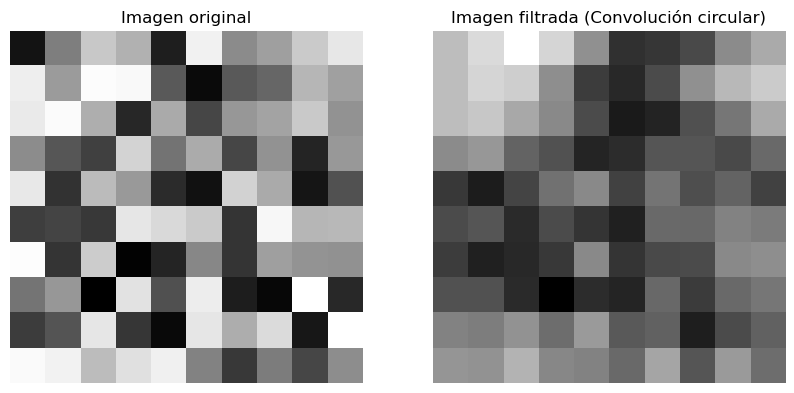

Matriz original: 
 [[ 19 126 200 177  30 241 139 159 202 231]
 [238 155 252 249  90  10  90 102 182 160]
 [234 251 174  39 170  70 151 164 201 146]
 [140  86  64 212 115 171  70 146  37 152]
 [232  50 187 153  43  17 210 170  21  81]
 [ 62  68  57 230 217 202  52 247 182 184]
 [253  53 204   2  37 135  52 159 147 145]
 [116 151   0 226  80 237  29   7 255  40]
 [ 61  84 230  54   9 230 173 219  23 255]
 [250 242 188 224 240 130  57 124  70 141]] 

Matriz filtrada: 
 [[173 185 201 183 154 114 116 124 152 165]
 [173 183 180 153 119 110 125 154 171 179]
 [173 177 164 151 125 104 108 127 143 165]
 [152 157 135 128 109 112 129 129 124 138]
 [117 105 122 141 151 121 142 126 135 121]
 [125 129 111 125 115 107 138 137 148 145]
 [119 107 110 117 151 115 124 125 151 153]
 [128 128 111  93 112 109 137 118 138 143]
 [148 146 155 139 158 131 134 106 125 134]
 [156 155 169 150 148 138 163 129 158 139]]


In [5]:
cf3 = np.ones((3,3))

im_random_10 = np.random.randint(0, 256, size=(10, 10), dtype=np.uint8)

# Aplicamos el filtrado circular
res_cir = filtroCir(im_random_10, cf3) 

print("Matriz original: \n",im_random_10, "\n")
print("Matriz filtrada: \n", res_cir)